# Quan sát kết quả Kafka + Spark Structured Streaming

Notebook này đọc **một lần chạy đã ghi ra thư mục `output`**: số sự kiện Kafka được truy vấn điểm tiêu thụ, các micro-batch, điểm theo cửa sổ, gợi ý, giao dịch, phiên đã đóng và bản lưu sự kiện thô. Nó không thay thế Spark UI hay theo dõi trực tiếp từng trigger; sau khi pipeline ghi thêm dữ liệu, chạy lại các cell từ phần **Nạp ảnh chụp output**.

**Cách dùng:** cài `pandas pyarrow matplotlib ipykernel jupyter` trong môi trường notebook; sửa duy nhất `OUTPUT_FOLDER` ở cell dưới, rồi **Run All**. Thư mục có thể là tên trong gốc dự án, đường dẫn tương đối hoặc đường dẫn tuyệt đối. Dữ liệu chỉ được đọc. Cell cuối cho phép đổi `SELECTED_BATCH_ID` để xem riêng một batch điểm.

**Phân biệt số liệu:** `num_input_rows` là số thông điệp Kafka của batch tính điểm; `aggregate_update_count` là số dòng tổng hợp theo cửa sổ được cập nhật (một event có thể tác động hai cửa sổ). `raw_events/batch_id=...` có batch ID riêng của truy vấn lưu thô. Notebook nối hai truy vấn bằng topic, partition và khoảng offset `[start, end)`. Một trigger không tạo micro-batch mới khi truy vấn đang rảnh sẽ không có `batch_id` trong output.

In [34]:
from pathlib import Path
from collections import Counter, defaultdict
from functools import reduce
import csv
import json
import re

import pandas as pd
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# CHỈ CẦN ĐỔI DÒNG NÀY KHI DÙNG THƯ MỤC OUTPUT KHÁC.
OUTPUT_FOLDER = "output_500_20261019-220740-76542"

# Để None sẽ hiện toàn bộ dòng của batch được chọn. Đặt 100/500 nếu batch lớn.
MAX_ROWS_PER_TABLE = None


def find_output(value):
    path = Path(value).expanduser()
    choices = [path] if path.is_absolute() else [Path.cwd() / path, Path.cwd().parent / path]
    for choice in choices:
        if choice.is_dir():
            return choice.resolve()
    raise FileNotFoundError(f"Không tìm thấy output {value!r}. Đã thử: {choices}")

OUTPUT_DIR = find_output(OUTPUT_FOLDER)
PROJECT_ROOT = next((p for p in [OUTPUT_DIR.parent, Path.cwd(), Path.cwd().parent]
                     if (p / "README.md").exists() and (p / "data").exists()), None)
CSV_PATH = PROJECT_ROOT / "data/events_sorted.csv" if PROJECT_ROOT else None
print("Output:", OUTPUT_DIR)
print("CSV gốc:", CSV_PATH if CSV_PATH and CSV_PATH.exists() else "không tìm thấy; vẫn xem được output")

Output: /Users/macbook/Documents/Nam4/BigData/retail-rocket-streaming-demo/output_500_20261019-220740-76542
CSV gốc: /Users/macbook/Documents/Nam4/BigData/retail-rocket-streaming-demo/data/events_sorted.csv


## 1. Nạp ảnh chụp output

Chạy lại cell này và các cell bên dưới nếu Spark vừa ghi thêm batch. Chỉ đọc thư mục batch có dấu `_SUCCESS` để tránh thấy dữ liệu Parquet/JSON đang ghi dở. Một lần chạy cũ có thể thiếu `raw_events/` hoặc `intent_input_offsets/`; notebook sẽ ghi rõ phần nào không xem được.

In [35]:
BATCH_RE = re.compile(r"^batch_id=(\d+)$")


def batch_id(path):
    match = BATCH_RE.match(path.name)
    return int(match.group(1)) if match else None


def batch_dirs(section):
    root = OUTPUT_DIR / section
    return {batch_id(p): p for p in root.glob("batch_id=*")
            if p.is_dir() and batch_id(p) is not None and (p / "_SUCCESS").exists()}


def json_manifests(section):
    result = {}
    for path in (OUTPUT_DIR / section).glob("batch_id=*.json"):
        try:
            result[int(path.stem.split("=")[1])] = json.loads(path.read_text(encoding="utf-8"))
        except (ValueError, OSError) as error:
            print(f"Bỏ qua manifest lỗi {path}: {error}")
    return result


def part_files(folder, suffix):
    paths = sorted(folder.rglob(f"part-*{suffix}")) if folder else []
    if suffix != ".parquet":
        return paths
    # Spark can write a valid empty Parquet part (0 row groups) for a batch
    # with no rows. PyArrow raises when read() is called on that file.
    return [path for path in paths if pq.ParquetFile(path).metadata.num_row_groups > 0]


def parquet_rows(folder):
    return sum(pq.ParquetFile(path).metadata.num_rows for path in part_files(folder, ".parquet"))


def json_rows(folder):
    return sum(1 for path in part_files(folder, ".json")
               for line in path.open(encoding="utf-8") if line.strip())


def read_json_batch(section, number):
    folder = batch_dirs_by_section.get(section, {}).get(number)
    rows = [json.loads(line) for path in part_files(folder, ".json")
            for line in path.open(encoding="utf-8") if line.strip()]
    return pd.DataFrame(rows)


def read_parquet_batch(section, number):
    folder = batch_dirs_by_section.get(section, {}).get(number)
    frames = []
    for path in part_files(folder, ".parquet"):
        frame = pq.ParquetFile(path).read().to_pandas()
        if "event_date" not in frame and "event_date=" in str(path):
            frame["event_date"] = next(p.name.split("=", 1)[1] for p in path.parents
                                       if p.name.startswith("event_date="))
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


sections = ["intent", "recommendations", "purchases", "recommendation_history", "sessions", "raw_events"]
batch_dirs_by_section = {name: batch_dirs(name) for name in sections}
offsets = json_manifests("intent_input_offsets")
metrics = json_manifests("micro_batches")
raw_files = [p for folder in batch_dirs_by_section["raw_events"].values()
             for p in part_files(folder, ".parquet")]

intent_ids = sorted(set(offsets) | set(metrics) | set(batch_dirs_by_section["intent"]))
records = []
for number in intent_ids:
    row = {"batch_id": number,
           "kafka_input_rows": offsets.get(number, {}).get("num_input_rows"),
           "aggregate_update_count": metrics.get(number, {}).get("aggregate_update_count"),
           "intent_parquet_rows": parquet_rows(batch_dirs_by_section["intent"].get(number)),
           "recommendations": json_rows(batch_dirs_by_section["recommendations"].get(number)),
           "purchased_pairs": parquet_rows(batch_dirs_by_section["purchases"].get(number)),
           "closed_sessions": parquet_rows(batch_dirs_by_section["sessions"].get(number)),
           "duration_ms_callback": metrics.get(number, {}).get("duration_ms"),
           "completed_at_epoch_ms": metrics.get(number, {}).get("completed_at_epoch_ms")}
    records.append(row)
batch_overview = pd.DataFrame(records)
raw_batch_overview = pd.DataFrame([
    {"raw_batch_id": number, "archived_rows": parquet_rows(folder)}
    for number, folder in sorted(batch_dirs_by_section["raw_events"].items())])
raw_total = int(raw_batch_overview["archived_rows"].sum()) if not raw_batch_overview.empty else 0
kafka_total = (int(batch_overview["kafka_input_rows"].dropna().sum())
               if offsets and not batch_overview.empty and "kafka_input_rows" in batch_overview else None)
rec_total = int(batch_overview["recommendations"].sum()) if not batch_overview.empty else 0
csv_total = None
if CSV_PATH and CSV_PATH.exists():
    with CSV_PATH.open(encoding="utf-8-sig") as source:
        csv_total = max(sum(1 for _ in source) - 1, 0)

summary = pd.DataFrame([
    ("Micro-batch điểm quan sát được", len(intent_ids)),
    ("Batch có manifest Kafka", len(offsets)),
    ("Thông điệp Kafka vào truy vấn điểm", kafka_total if kafka_total is not None else "không có manifest"),
    ("Số sự kiện trong CSV gốc", csv_total if csv_total is not None else "không tìm thấy CSV"),
    ("Tỷ lệ đã đọc so với CSV", f"{kafka_total / csv_total:.2%}" if csv_total and kafka_total is not None else "không xác định"),
    ("Sự kiện trong kho thô", raw_total if raw_files else "không có kho thô"),
    ("Batch của truy vấn lưu thô", len(raw_batch_overview)),
    ("Gợi ý đã ghi", rec_total),
    ("Phiên đã đóng", int(batch_overview["closed_sessions"].sum()) if not batch_overview.empty else 0),
], columns=["Chỉ số", "Giá trị"])
display(summary)
if kafka_total is not None and raw_files and kafka_total != raw_total:
    display(Markdown("⚠️ Số dòng kho thô khác số thông điệp truy vấn điểm. Hai truy vấn đọc Kafka độc lập; kiểm tra offset, thời điểm hoàn tất và cấu hình của lần chạy."))
if not raw_files:
    display(Markdown("⚠️ Không có `raw_events/`: không thể liệt kê chính xác các sự kiện đã vào một batch điểm."))
if not offsets:
    display(Markdown("⚠️ Không có `intent_input_offsets/`: không thể nối sự kiện thô với batch điểm."))

,Chỉ số,Giá trị
0,Micro-batch điểm quan sát được,7
1,Batch có manifest Kafka,7
2,Thông điệp Kafka vào truy vấn điểm,500
3,Số sự kiện trong CSV gốc,2756101
4,Tỷ lệ đã đọc so với CSV,0.02%
5,Sự kiện trong kho thô,500
6,Batch của truy vấn lưu thô,10
7,Gợi ý đã ghi,13
8,Phiên đã đóng,0


## 2. Mỗi micro-batch đã xử lý gì?

Bảng dưới tổng hợp **batch của truy vấn điểm**, gồm số event Kafka đầu vào, số bản cập nhật cửa sổ, thời gian callback, số gợi ý và phiên đã đóng. `closed_sessions` chỉ tính các file phiên mang cùng số batch của **truy vấn phiên độc lập**; số đó không có quan hệ nhân quả với batch điểm cùng ID. Xem bảng riêng phía dưới nếu cần theo dõi phiên. Các batch rỗng hoặc truy vấn đang rảnh có thể không xuất hiện trong các thư mục kết quả.

,batch_id,kafka_input_rows,aggregate_update_count,intent_parquet_rows,recommendations,purchased_pairs,closed_sessions,duration_ms_callback,completed_at_epoch_ms
0,0,273,511,511,6,0,0,14074.22,1792422544651
1,1,80,147,147,2,0,0,7983.31,1792422552894
2,2,42,76,76,2,0,0,5393.58,1792422558479
3,3,28,54,54,1,0,0,5053.46,1792422563671
4,4,39,70,70,0,1,0,5417.93,1792422569844
5,5,38,68,68,2,0,0,6281.14,1792422576323
6,6,0,0,0,0,0,0,1947.39,1792422578378


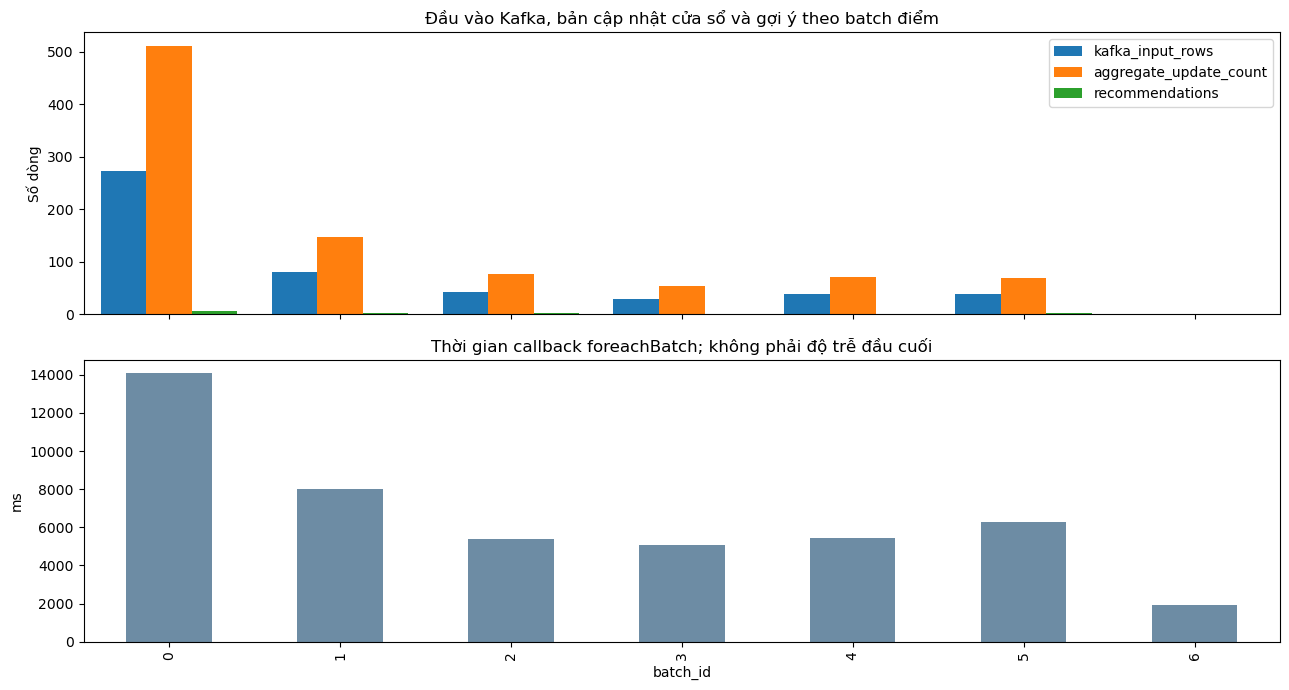

In [36]:
if batch_overview.empty:
    display(Markdown("Chưa có micro-batch điểm được ghi trong output này."))
else:
    display(batch_overview.sort_values("batch_id").reset_index(drop=True))
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    batch_overview.plot(x="batch_id", y=["kafka_input_rows", "aggregate_update_count", "recommendations"],
                        kind="bar", ax=axes[0], width=.8)
    axes[0].set_ylabel("Số dòng")
    axes[0].set_title("Đầu vào Kafka, bản cập nhật cửa sổ và gợi ý theo batch điểm")
    batch_overview.plot(x="batch_id", y="duration_ms_callback", kind="bar", ax=axes[1], legend=False,
                        color="#6d8ca4")
    axes[1].set_ylabel("ms")
    axes[1].set_title("Thời gian callback foreachBatch; không phải độ trễ đầu cuối")
    plt.tight_layout()
    plt.show()

## 3. Dữ liệu thô nào đã được lưu?

Bảng đầu là các batch của **truy vấn lưu thô**. Bảng xem trước lấy từ Parquet và giữ cả `raw_json`, `event_time` lịch sử, `kafka_timestamp` lúc gửi lại, topic, partition và offset. Kafka chỉ giữ thứ tự **trong từng phân vùng**; sắp xếp toàn bộ theo offset không khôi phục được thứ tự CSV tuyệt đối. Muốn xem tất cả các dòng thô, dùng cell chọn batch ở cuối hoặc tăng `RAW_PREVIEW_ROWS`.

In [37]:
RAW_PREVIEW_ROWS = 30
if raw_batch_overview.empty:
    display(Markdown("Không có bản lưu thô trong output này (`ARCHIVE_RAW_EVENTS` có thể đã tắt)."))
else:
    display(raw_batch_overview)
    preview = []
    for path in raw_files:
        for arrow_batch in pq.ParquetFile(path).iter_batches(batch_size=RAW_PREVIEW_ROWS):
            preview.append(arrow_batch.to_pandas())
            if sum(len(frame) for frame in preview) >= RAW_PREVIEW_ROWS:
                break
        if sum(len(frame) for frame in preview) >= RAW_PREVIEW_ROWS:
            break
    raw_preview = pd.concat(preview, ignore_index=True).head(RAW_PREVIEW_ROWS) if preview else pd.DataFrame()
    display(raw_preview)

,raw_batch_id,archived_rows
0,0,273
1,1,13
2,2,20
3,3,24
4,4,24
5,5,24
6,6,32
7,7,21
8,8,39
9,9,30


,kafka_topic,kafka_partition,kafka_offset,kafka_timestamp,kafka_key,raw_json,event_timestamp_ms,event_time,visitorid,event,itemid,transactionid,batch_id
0,retail-rocket-events,1,99,2026-10-19 15:08:55.021,628233,"{""timestamp"": 1430623151355, ""visitorid"": 6282...",1430623151355,2015-05-03 03:19:11.355,628233,view,422993,NaN,3
1,retail-rocket-events,1,100,2026-10-19 15:08:55.743,1099963,"{""timestamp"": 1430623165746, ""visitorid"": 1099...",1430623165746,2015-05-03 03:19:25.746,1099963,view,260521,NaN,3
2,retail-rocket-events,1,101,2026-10-19 15:08:58.607,630669,"{""timestamp"": 1430623222657, ""visitorid"": 6306...",1430623222657,2015-05-03 03:20:22.657,630669,view,335975,NaN,3
3,retail-rocket-events,1,102,2026-10-19 15:08:59.520,294502,"{""timestamp"": 1430623238654, ""visitorid"": 2945...",1430623238654,2015-05-03 03:20:38.654,294502,view,52039,NaN,3
4,retail-rocket-events,1,103,2026-10-19 15:08:59.619,50842,"{""timestamp"": 1430623240624, ""visitorid"": 5084...",1430623240624,2015-05-03 03:20:40.624,50842,view,447669,NaN,3
5,retail-rocket-events,0,114,2026-10-19 15:08:56.113,185504,"{""timestamp"": 1430623173124, ""visitorid"": 1855...",1430623173124,2015-05-03 03:19:33.124,185504,view,66974,NaN,3
6,retail-rocket-events,0,115,2026-10-19 15:08:56.538,1375898,"{""timestamp"": 1430623181541, ""visitorid"": 1375...",1430623181541,2015-05-03 03:19:41.541,1375898,view,139725,NaN,3
7,retail-rocket-events,0,116,2026-10-19 15:08:57.183,780907,"{""timestamp"": 1430623194408, ""visitorid"": 7809...",1430623194408,2015-05-03 03:19:54.408,780907,view,41821,NaN,3
8,retail-rocket-events,0,117,2026-10-19 15:08:57.744,122517,"{""timestamp"": 1430623205603, ""visitorid"": 1225...",1430623205603,2015-05-03 03:20:05.603,122517,view,75694,NaN,3
9,retail-rocket-events,0,118,2026-10-19 15:08:57.907,277500,"{""timestamp"": 1430623208843, ""visitorid"": 2775...",1430623208843,2015-05-03 03:20:08.843,277500,view,186765,NaN,3


In [38]:
event_counts = Counter()
partition_counts = Counter()
event_min = None
event_max = None
for path in raw_files:
    for arrow_batch in pq.ParquetFile(path).iter_batches(
            columns=["event", "kafka_partition", "event_time"], batch_size=65536):
        frame = arrow_batch.to_pandas()
        event_counts.update(frame["event"].dropna())
        partition_counts.update(frame["kafka_partition"].dropna().astype(int))
        times = frame["event_time"].dropna()
        if not times.empty:
            event_min = min(event_min, times.min()) if event_min is not None else times.min()
            event_max = max(event_max, times.max()) if event_max is not None else times.max()
if raw_files:
    display(Markdown(f"**Khoảng thời gian sự kiện đã lưu:** {event_min} → {event_max}. Đây là thời gian lịch sử trong dữ liệu, không phải lúc Kafka nhận lại."))
    display(pd.DataFrame(event_counts.items(), columns=["loại_event", "số_lần"]).sort_values("số_lần", ascending=False))
    display(pd.DataFrame(partition_counts.items(), columns=["kafka_partition", "số_dòng"]).sort_values("kafka_partition"))
else:
    print("Thiếu kho thô; không thể thống kê loại sự kiện và phân vùng của toàn bộ input.")


**Khoảng thời gian sự kiện đã lưu:** 2015-05-03 03:00:04.384000 → 2015-05-03 03:30:19.204000. Đây là thời gian lịch sử trong dữ liệu, không phải lúc Kafka nhận lại.

,loại_event,số_lần
0,view,485
1,addtocart,14
2,transaction,1


,kafka_partition,số_dòng
1,0,204
0,1,155
2,2,141


## 4. Ai được gợi ý sản phẩm gì?

Mỗi dòng JSON gợi ý có `visitorid`, `interested_itemid`, `recommended_itemid`, điểm ý định, cửa sổ, phương pháp và thời gian tạo. Bảng theo batch và khách được tính bằng cách đọc JSON từng dòng, không cần nạp toàn bộ gợi ý của tập lớn vào RAM. Một gợi ý đã ghi không tự bị thu hồi nếu sự kiện mua đến sau.

In [39]:
rec_by_visitor = Counter()
rec_examples = []
for number, folder in sorted(batch_dirs_by_section["recommendations"].items()):
    for path in part_files(folder, ".json"):
        with path.open(encoding="utf-8") as source:
            for line in source:
                if not line.strip():
                    continue
                item = json.loads(line)
                rec_by_visitor[item.get("visitorid")] += 1
                if len(rec_examples) < 100:
                    rec_examples.append(item)
if rec_examples:
    display(pd.DataFrame(rec_examples))
    display(pd.DataFrame(rec_by_visitor.most_common(20), columns=["visitorid", "số_gợi_ý"]))
    if rec_total > len(rec_examples):
        print(f"Đang hiển thị {len(rec_examples)}/{rec_total} gợi ý. Chọn batch bên dưới để xem toàn bộ gợi ý của batch đó.")
else:
    display(Markdown("Chưa có gợi ý nào được ghi."))

,visitorid,interested_itemid,recommended_itemid,intent_score,window_start,window_end,recommendation_time,batch_id,method,candidate_score
0,319455,342530,407658,5,2015-05-03T03:05:00.000Z,2015-05-03T03:15:00.000Z,2026-10-19T15:09:02.633Z,0,co_view_topk,15
1,979664,338222,190545,5,2015-05-03T03:00:00.000Z,2015-05-03T03:10:00.000Z,2026-10-19T15:09:02.633Z,0,co_view_topk,4
2,345781,438400,313931,6,2015-05-03T03:05:00.000Z,2015-05-03T03:15:00.000Z,2026-10-19T15:09:02.633Z,0,co_view_topk,1
3,260113,125751,95808,6,2015-05-03T02:55:00.000Z,2015-05-03T03:05:00.000Z,2026-10-19T15:09:02.633Z,0,co_view_topk,9
4,693516,297662,83730,11,2015-05-03T03:00:00.000Z,2015-05-03T03:10:00.000Z,2026-10-19T15:09:02.633Z,0,co_view_topk,1
5,1375898,461547,205777,6,2015-05-03T03:10:00.000Z,2015-05-03T03:20:00.000Z,2026-10-19T15:09:02.633Z,0,co_view_topk,5
6,726427,415660,52039,8,2015-05-03T03:10:00.000Z,2015-05-03T03:20:00.000Z,2026-10-19T15:09:09.216Z,1,co_view_topk,3
7,1099963,260521,89931,7,2015-05-03T03:10:00.000Z,2015-05-03T03:20:00.000Z,2026-10-19T15:09:09.216Z,1,co_view_topk,1
8,266417,445106,301721,6,2015-05-03T03:15:00.000Z,2015-05-03T03:25:00.000Z,2026-10-19T15:09:17.203Z,2,co_view_topk,5
9,869008,40685,253188,6,2015-05-03T03:20:00.000Z,2015-05-03T03:30:00.000Z,2026-10-19T15:09:17.203Z,2,co_view_topk,1


,visitorid,số_gợi_ý
0,266417,2
1,319455,1
2,979664,1
3,345781,1
4,260113,1
5,693516,1
6,1375898,1
7,726427,1
8,1099963,1
9,869008,1


## 5. Phiên, giao dịch và trạng thái cửa sổ

`sessions/` chỉ chứa phiên đã đóng theo watermark. `purchases/` là các cặp khách/sản phẩm mua được ghi theo batch, không phải toàn bộ transaction thô. `intent/` là **các bản cập nhật**, vì vậy cộng các dòng Parquet lại sẽ đếm lặp một khóa cửa sổ qua nhiều batch. Cell dưới cho biết dung lượng từng đầu ra; cell chọn batch cho xem nội dung thực tế.

In [40]:
output_inventory = pd.DataFrame([
    {"đầu_ra": section,
     "số_thư_mục_batch_hoàn_tất": len(batch_dirs_by_section[section]),
     "số_dòng_đã_ghi": sum((json_rows(folder) if section == "recommendations" else parquet_rows(folder))
                              for folder in batch_dirs_by_section[section].values())}
    for section in sections
])
display(output_inventory)
if not batch_dirs_by_section["sessions"]:
    display(Markdown("Chưa có phiên đóng trong output này. Watermark theo thời gian sự kiện phải vượt cuối phiên; producer dừng không tự đóng phiên."))

,đầu_ra,số_thư_mục_batch_hoàn_tất,số_dòng_đã_ghi
0,intent,7,926
1,recommendations,7,13
2,purchases,7,1
3,recommendation_history,7,13
4,sessions,0,0
5,raw_events,10,500


Chưa có phiên đóng trong output này. Watermark theo thời gian sự kiện phải vượt cuối phiên; producer dừng không tự đóng phiên.

## 6. Đối chiếu với CSV gốc: có đúng N dòng đầu không?

Output **không lưu số thứ tự dòng CSV**. Với output nhỏ (tối đa 20.000 dòng), cell này tự đối chiếu **đa tập nội dung sự kiện** trong kho thô với đúng N dòng đầu của `data/events_sorted.csv`, trong đó N là số bản ghi thô. Kết quả “khớp” xác nhận nội dung, không chứng minh thứ tự gửi liên phân vùng hoặc cấu hình producer. Với output lớn, cell bỏ qua phép đối chiếu để tránh giữ hàng triệu dòng trong RAM; số lượng đã xử lý vẫn hiện ở phần đầu.

In [41]:
COMPARE_FIRST_N_MAX = 20_000

def canonical_event(row):
    return (int(row["timestamp"]), int(row["visitorid"]), str(row["event"]),
            int(row["itemid"]), None if row.get("transactionid") in (None, "") else int(row["transactionid"]))

if not CSV_PATH or not CSV_PATH.exists():
    print("Không tìm thấy CSV gốc để đối chiếu; xem thống kê chỉ từ output ở trên.")
elif not raw_files:
    print("Output không có raw_events/ nên không thể đối chiếu từng sự kiện.")
elif raw_total > COMPARE_FIRST_N_MAX:
    print(f"Có {raw_total:,} sự kiện; bỏ qua đối chiếu đa tập để tránh dùng nhiều RAM.")
else:
    actual = Counter()
    for path in raw_files:
        for arrow_batch in pq.ParquetFile(path).iter_batches(columns=["raw_json"], batch_size=4096):
            actual.update(canonical_event(json.loads(value)) for value in arrow_batch.column(0).to_pylist())
    expected = Counter()
    with CSV_PATH.open(encoding="utf-8-sig", newline="") as source:
        reader = csv.DictReader(source)
        for _, row in zip(range(raw_total), reader):
            expected[canonical_event(row)] += 1
    print(f"Số dòng lưu thô: {raw_total:,}")
    print(f"Khớp đúng {raw_total:,} dòng đầu CSV (kể cả số lần lặp):", "CÓ" if actual == expected else "KHÔNG")
    if actual != expected:
        print("Có thể producer dùng SKIP/LIMIT khác, gửi lại sự kiện, hoặc kho thô chưa theo kịp.")

Số dòng lưu thô: 500
Khớp đúng 500 dòng đầu CSV (kể cả số lần lặp): CÓ


## 7. Chọn **một batch điểm** để xem toàn bộ thông tin

Chỉ đổi `SELECTED_BATCH_ID`, rồi chạy cell này. Notebook hiển thị manifest Kafka, khoảng offset, **sự kiện thô thực sự vào batch điểm**, điểm theo cửa sổ, gợi ý và các đầu ra mang cùng ID. Cột `raw_batch_id` trong bảng sự kiện cho thấy sự kiện đó đã được lưu bởi batch nào của truy vấn thô.

**Lưu ý:** `sessions/batch_id=n` thuộc truy vấn phiên độc lập. Nó được hiển thị để tiện tra cứu theo số, nhưng không phải kết quả do batch điểm `n` trực tiếp tạo ra. Nếu Spark không ghi `startOffset` của batch đầu, notebook chỉ suy ra offset đầu từ dữ liệu đã lưu khi tổng số suy ra khớp `num_input_rows`; nếu không đủ bằng chứng sẽ báo không thể xác định chính xác thay vì đoán.

In [42]:
# CHỈ CẦN ĐỔI SỐ NÀY ĐỂ XEM BATCH ĐIỂM KHÁC.
SELECTED_BATCH_ID = 0


def parse_offsets(value):
    if value is None:
        return None
    return json.loads(value) if isinstance(value, str) else value


def archive_min_offsets():
    minimum = {}
    if not raw_files:
        return minimum
    scanner = ds.dataset([str(p) for p in raw_files], format="parquet").scanner(
        columns=["kafka_topic", "kafka_partition", "kafka_offset"], batch_size=65536)
    for arrow_batch in scanner.to_batches():
        frame = arrow_batch.to_pandas()
        for (topic, partition), offset in frame.groupby(["kafka_topic", "kafka_partition"])["kafka_offset"].min().items():
            key = (topic, int(partition))
            minimum[key] = min(minimum.get(key, int(offset)), int(offset))
    return minimum


def offset_ranges(number):
    manifest = offsets.get(number)
    if not manifest:
        return [], "Thiếu intent_input_offsets của batch này."
    sources = manifest.get("sources", [])
    ranges = []
    for source in sources:
        end = parse_offsets(source.get("endOffset"))
        start = parse_offsets(source.get("startOffset"))
        if not end:
            continue
        if start is None and number > 0:
            previous = offsets.get(number - 1, {}).get("sources", [])
            start = parse_offsets(previous[0].get("endOffset")) if previous else None
        if start is None:
            # Trường hợp Spark không công bố startOffset của batch đầu.
            end_total = sum(int(value) for parts in end.values() for value in parts.values())
            expected = manifest.get("num_input_rows")
            if expected is not None and end_total == int(expected):
                start = {topic: {partition: 0 for partition in parts} for topic, parts in end.items()}
            elif raw_files and expected is not None:
                minima = archive_min_offsets()
                candidate = {topic: {partition: minima.get((topic, int(partition)))
                                     for partition in parts} for topic, parts in end.items()}
                if all(value is not None for parts in candidate.values() for value in parts.values()):
                    total = sum(int(value) - int(candidate[topic][partition])
                                for topic, parts in end.items() for partition, value in parts.items())
                    if total == int(expected):
                        start = candidate
        if start is None:
            return [], "Không đủ dữ liệu để xác định startOffset chính xác cho batch này."
        for topic, parts in end.items():
            for partition, stop in parts.items():
                begin = start.get(topic, {}).get(partition)
                if begin is None:
                    return [], f"Thiếu startOffset của {topic}, partition {partition}."
                if int(stop) > int(begin):
                    ranges.append((topic, int(partition), int(begin), int(stop)))
    return ranges, None


def raw_events_for_intent_batch(number):
    ranges, problem = offset_ranges(number)
    if problem or not ranges or not raw_files:
        return pd.DataFrame(), ranges, problem or ("Thiếu kho thô." if not raw_files else None)
    dataset = ds.dataset([str(p) for p in raw_files], format="parquet")
    predicates = [(ds.field("kafka_topic") == topic) & (ds.field("kafka_partition") == partition)
                  & (ds.field("kafka_offset") >= begin) & (ds.field("kafka_offset") < stop)
                  for topic, partition, begin, stop in ranges]
    frame = dataset.to_table(filter=reduce(lambda a, b: a | b, predicates)).to_pandas()
    if not frame.empty:
        frame = frame.rename(columns={"batch_id": "raw_batch_id"})
        frame = frame.sort_values(["kafka_topic", "kafka_partition", "kafka_offset"]).reset_index(drop=True)
    return frame, ranges, None


def show_table(title, frame):
    display(Markdown(f"### {title} — {len(frame):,} dòng"))
    if frame.empty:
        print("Không có dòng nào được ghi.")
    else:
        shown = frame if MAX_ROWS_PER_TABLE is None else frame.head(MAX_ROWS_PER_TABLE)
        with pd.option_context("display.max_rows", None, "display.max_columns", None,
                               "display.max_colwidth", 140):
            display(shown)
        if len(shown) < len(frame):
            print(f"Đang hiện {len(shown):,}/{len(frame):,} dòng; đặt MAX_ROWS_PER_TABLE = None để hiện tất cả.")


number = int(SELECTED_BATCH_ID)
if number not in intent_ids:
    print(f"Không có batch điểm {number}. ID hiện có: {intent_ids}")
else:
    display(Markdown(f"## Batch điểm {number}"))
    display(batch_overview.loc[batch_overview.batch_id == number].T.rename(columns={
        batch_overview.index[batch_overview.batch_id == number][0]: "giá trị"}))
    manifest = offsets.get(number)
    if manifest:
        display(Markdown("### Manifest Kafka"))
        display(pd.json_normalize(manifest, sep="."))
    events, ranges, problem = raw_events_for_intent_batch(number)
    if ranges:
        display(pd.DataFrame(ranges, columns=["topic", "partition", "start_offset", "end_offset_exclusive"]))
    if problem:
        display(Markdown(f"⚠️ {problem}"))
    if manifest and raw_files and not problem and len(events) != manifest.get("num_input_rows"):
        display(Markdown(f"⚠️ Kho thô tìm được {len(events)} dòng, Spark báo {manifest.get('num_input_rows')}; truy vấn lưu thô có thể chưa theo kịp hoặc dữ liệu chưa đủ."))
    show_table("Sự kiện Kafka thực sự vào batch điểm", events)
    if not events.empty:
        display(events.groupby("event", dropna=False).size().rename("số_event").reset_index())
        display(events.groupby("visitorid", dropna=False).size().sort_values(ascending=False)
                .head(20).rename("số_event").reset_index())
    show_table("Bản cập nhật điểm theo cửa sổ", read_parquet_batch("intent", number))
    show_table("Gợi ý được ghi bởi batch điểm", read_json_batch("recommendations", number))
    show_table("Cặp khách/sản phẩm mua được ghi bởi batch điểm", read_parquet_batch("purchases", number))
    show_table("Lịch sử gợi ý được ghi bởi batch điểm", read_parquet_batch("recommendation_history", number))
    show_table("Phiên có cùng batch ID trong truy vấn phiên độc lập", read_parquet_batch("sessions", number))
    display(Markdown("### Số liệu callback"))
    display(pd.DataFrame([metrics.get(number, {})]))

## Batch điểm 0

,giá trị
batch_id,0.000000e+00
kafka_input_rows,2.730000e+02
aggregate_update_count,5.110000e+02
intent_parquet_rows,5.110000e+02
recommendations,6.000000e+00
purchased_pairs,0.000000e+00
closed_sessions,0.000000e+00
duration_ms_callback,1.407422e+04
completed_at_epoch_ms,1.792423e+12


### Manifest Kafka

,batch_id,query_name,num_input_rows,sources
0,0,retail-rocket-intent,273,[{'description': 'KafkaV2[Subscribe[retail-roc...


,topic,partition,start_offset,end_offset_exclusive
0,retail-rocket-events,2,0,82
1,retail-rocket-events,1,0,89
2,retail-rocket-events,0,0,102


...

,visitorid,interested_itemid,recommended_itemid,intent_score,window_start,window_end,recommendation_time,batch_id,method,candidate_score
0,319455,342530,407658,5,2015-05-03 03:05:00,2015-05-03 03:15:00,2026-10-19 15:09:03.701084,0,co_view_topk,15
1,979664,338222,190545,5,2015-05-03 03:00:00,2015-05-03 03:10:00,2026-10-19 15:09:03.701084,0,co_view_topk,4
2,345781,438400,313931,6,2015-05-03 03:05:00,2015-05-03 03:15:00,2026-10-19 15:09:03.701084,0,co_view_topk,1
3,260113,125751,95808,6,2015-05-03 02:55:00,2015-05-03 03:05:00,2026-10-19 15:09:03.701084,0,co_view_topk,9
4,693516,297662,83730,11,2015-05-03 03:00:00,2015-05-03 03:10:00,2026-10-19 15:09:03.701084,0,co_view_topk,1
5,1375898,461547,205777,6,2015-05-03 03:10:00,2015-05-03 03:20:00,2026-10-19 15:09:03.701084,0,co_view_topk,5


### Phiên có cùng batch ID trong truy vấn phiên độc lập — 0 dòng

Không có dòng nào được ghi.


### Số liệu callback

,batch_id,aggregate_update_count,duration_ms,completed_at_epoch_ms
0,0,511,14074.22,1792422544651


## Cách đọc kết quả và giới hạn

- `kafka_input_rows` có thể bằng 500 trong lần chạy 500 dòng, nhưng `intent_parquet_rows` có thể lớn hơn vì một sự kiện nằm trong nhiều cửa sổ và một cửa sổ được cập nhật ở nhiều batch.
- `recommendations/` là lịch sử gợi ý đã phát, không phải danh sách gợi ý hiện còn hợp lệ sau mọi giao dịch về sau.
- `sessions/` rỗng không đồng nghĩa không có visitor: phiên chỉ xuất hiện khi watermark vượt `session_end`.
- Không thể suy ra **mọi lần trigger của bộ lập lịch** chỉ từ output; notebook đếm những micro-batch có tiến độ/kết quả được lưu. Nó cũng không đọc trạng thái nội bộ Spark hoặc Kafka nếu không được ghi ra output.
- Với output rất lớn, phần tổng quan chỉ dùng metadata Parquet và đếm dòng JSON; cell chọn batch chỉ nạp batch được yêu cầu. Việc hiện toàn bộ dòng của một batch lớn có thể làm notebook chậm; khi đó đặt `MAX_ROWS_PER_TABLE` thành một số hữu hạn.